Environment

In [1]:
libs = {
    "hypernet": "/home/zanardi/Codes/TC/HyperNet/hypernet",
    "pycomet": "/home/zanardi/Codes/ML/PyCOMET/pycomet"
}

In [2]:
import sys
for lib in libs.values():
    sys.path.append(lib)

Import libraries

In [3]:
import os
import json
import copy
import pycomet
import numpy as np
import scipy as sp

from scipy.linalg import expm
from silx.io.dictdump import h5todict

from hypernet import const
from pycomet.networks import FwdEulerIsoME
from hypernet.apps import utils as hyputils
from hypernet.thermophysics import specie_thermo as st_mod

Plotting

In [4]:
import matplotlib
from matplotlib import pyplot as plt
COLORS = matplotlib.rcParams['axes.prop_cycle'].by_key()['color']

path_to_figs = "./figs/"
os.makedirs(path_to_figs, exist_ok=True)

def plot_var(
    x=None,
    y=None,
    xref=None,
    yref=None,
    labels=[r'$t$ [s]', r'$X$'],
    scales=['log', 'log'],
    names=None,
    figname=None
):
    # Initialize figures
    fig = plt.figure()
    ax = fig.add_subplot()
    # x axis
    ax.set_xlabel(labels[0])
    ax.set_xscale(scales[0])
    # y axis
    ax.set_ylabel(labels[1])
    ax.set_yscale(scales[1])
    # Plotting
    n, d = y.shape if (x is not None) else yref.shape
    true_style = dict(
        lw=1
    )
    pred_style = dict(
        marker='^',
        fillstyle='none',
        markersize=5,
        markevery=n//20,
        ls='--',
        lw=1
    )
    for i in range(d):
        if (x is not None):
            ax.plot(x, y[:,i], c=COLORS[i], **pred_style)
        if (xref is not None):
            ax.plot(xref, yref[:,i], c=COLORS[i], **true_style)
        ax.plot([], [], c=COLORS[i], label=names[i])
    # plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
    plt.legend()
    if (figname is not None):
        fig.savefig(figname)
    plt.show()
    plt.close()

Initializing thermophysical models

In [5]:
with open("./../physics/inputs.full.json") as file:
    phyinp = json.load(file)
# Species thermo
sp_th = hyputils._get_specie_thermos(phyinp)
# Mixture
mix = hyputils._get_mixture(phyinp, sp_th)
# Kinetics
kin = hyputils._get_kinetics(phyinp, sp_th, mix)

Exact solution

In [6]:
def get_data(solution):
    t, T = [solution[k] for k in ('t', 'T')]
    na, nm = [solution[f"X_{s}"] * solution['n'] for s in sp_th.keys()]
    return t, na, nm, T

In [7]:
sol = h5todict(h5file='./../physics/solutions/full/solution.p1k.T1k.O05.hdf5')

In [8]:
t, na, nm, T = get_data(sol)
n = np.hstack([na, nm])
kin._update(n, T)

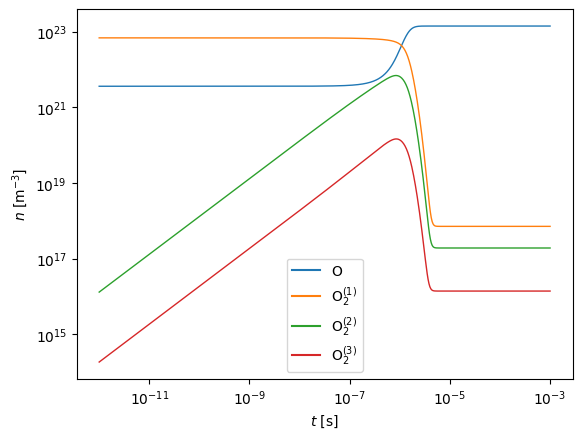

In [9]:
plot_var(
    xref=t.squeeze()[1:],
    yref=n[1:],
    labels=[r'$t$ [s]', r'$n$ [m$^{-3}$]'],
    scales=['log', 'log'],
    names=['O'] + [r'O$_2^{(%d)}$' % (i+1) for i in range(3)],
    figname=path_to_figs + "/solution"
)

Construct rate matrices

In [10]:
kef, keb = 0.0, 0.0
for reaction in kin.reactions:
    if (reaction.param['process'] in (5,6)):
        kef = kef + reaction.fwd.k.numpy().squeeze()[0]
        keb = keb + reaction.bwd.k.numpy().squeeze()[0]
    elif (reaction.param['process'] == 2):
        kd = reaction.fwd.k.numpy().squeeze()[0]
        kr = reaction.bwd.k.numpy().squeeze()[0]
ke = kef + keb.T
ke = (ke.T - np.diag(np.sum(ke, axis=-1)))

Governing equations

In [11]:
def fun(t, c):
    f = np.zeros_like(c)
    # Extract number densities
    n = c * const.UNA
    na, nm = n[0:1], n[1:]
    # Construct source terms
    we = np.matmul(ke,nm*na)
    wd = kd*nm*na - kr*na**3
    # Compose source terms
    f[0] = 2*np.sum(wd)
    f[1:] = we - wd
    return f / const.UNA

def solution(t, n0):
    res = sp.integrate.solve_ivp(
        fun=fun,
        t_span=[t[0],t[-1]],
        t_eval=t.squeeze(),
        y0=n0/const.UNA,
        method='LSODA',
        atol=1e-9,
        rtol=1e-7
    )
    return res.y.T * const.UNA

In [12]:
ntest = solution(t, n[0])

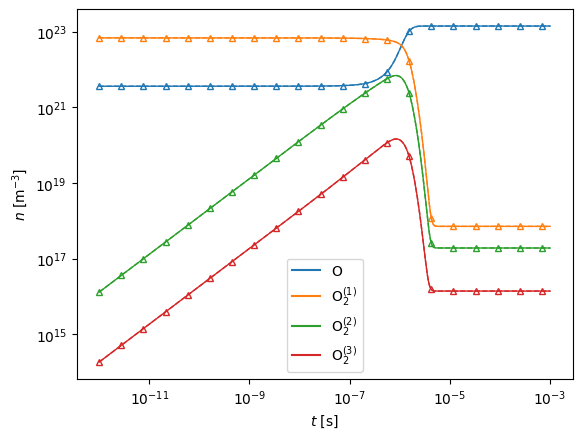

In [13]:
plot_var(
    x=t.squeeze()[1:],
    y=ntest[1:],
    xref=t.squeeze()[1:],
    yref=n[1:],
    labels=[r'$t$ [s]', r'$n$ [m$^{-3}$]'],
    scales=['log', 'log'],
    names=['O'] + [r'O$_2^{(%d)}$' % (i+1) for i in range(3)],
    figname=path_to_figs + "/solution"
)

Load master equation model

In [14]:
model = FwdEulerIsoME(
    processes=("exc", "dis"),
    rates={"kef": kef, "keb": keb, "kd": kd, "kr": kr}
)

In [15]:
dnmdt_true = np.vstack([fun(t=0, c=ni/const.UNA) for ni in n])[:,1:]

In [24]:
nt = len(t)
x = {
    "t": np.ones((nt,1)),
    "n": n,
    "f": np.zeros((nt,n.shape[1]-1))
}
dnmdt_pred = (model(list(x.values())) - n[:,1:]).numpy().squeeze() / const.UNA

na, nm [TensorShape([1000, 1]), TensorShape([1000, 3])]
kd,f [TensorShape([1, 3]), TensorShape([1000, 3])]
ke,kd,kr [TensorShape([1000, 3, 3]), TensorShape([1000, 3]), TensorShape([1000, 3])]
we [TensorShape([1000, 3])]
wed [TensorShape([1000, 3])]


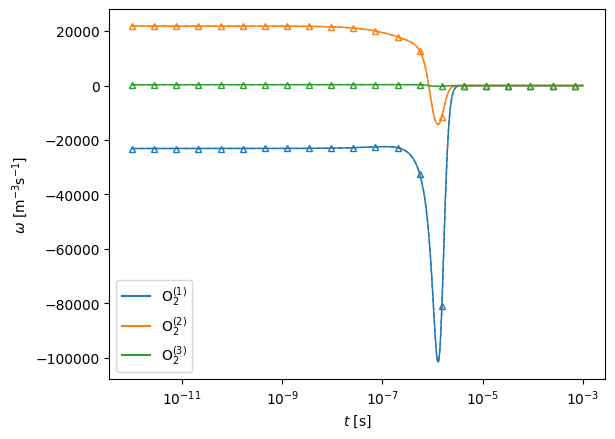

In [23]:
plot_var(
    x=t.squeeze()[1:],
    y=dnmdt_pred[1:],
    xref=t.squeeze()[1:],
    yref=dnmdt_true[1:],
    labels=[r'$t$ [s]', r'$\omega$ [m$^{-3}$s$^{-1}$]'],
    scales=['log', 'linear'],
    names=[r'O$_2^{(%d)}$' % (i+1) for i in range(dnmdt_true.shape[1])],
    figname=path_to_figs + "/source"
)